In [12]:
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from torchvision import transforms
from tqdm import tqdm

RESULTS_ROOT = Path("/content/Computer_vision_final/results")


def show_xai(dataset="nih", method="gradcam", index=0):
    root = RESULTS_ROOT / dataset / method
    meta = pd.read_csv(root / "metadata.csv")

    meta = meta[meta["gt_label"] == 1].reset_index(drop=True)
    row = meta.iloc[index]

    image = Image.open(row["image_path"]).convert("RGB")
    image = transforms.Compose([
        transforms.Resize(224),
        transforms.CenterCrop(224),
    ])(image)

    img = np.array(image).astype(np.float32) / 255.0

    if method == "gradcam":
        arr_path = row["cam_path"]
        title = "Grad-CAM"
    else:
        arr_path = row["ig_path"]
        title = "Integrated Gradients"

    heat = np.load(arr_path)
    boxes = json.loads(row["display_boxes_json"])

    heat_rgb = cv2.applyColorMap(np.uint8(255 * heat), cv2.COLORMAP_JET)
    heat_rgb = cv2.cvtColor(heat_rgb, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    overlay = np.clip(0.55 * img + 0.45 * heat_rgb, 0, 1)

    gt = row.get("gt_class", row.get("gt_label"))
    pred = row.get("pred_class", row.get("pred_label"))
    prob = row.get("pneumonia_probability", "NA")

    fig, axs = plt.subplots(1, 4, figsize=(16, 4))

    axs[0].imshow(img, cmap="gray")
    axs[0].set_title("Image")

    axs[1].imshow(img, cmap="gray")
    axs[1].set_title("GT box")
    for b in boxes:
        axs[1].add_patch(
            patches.Rectangle(
                (b["x"], b["y"]),
                b["width"],
                b["height"],
                linewidth=2,
                edgecolor="lime",
                facecolor="none",
            )
        )

    axs[2].imshow(heat, cmap="jet")
    axs[2].set_title(title)

    axs[3].imshow(overlay)
    axs[3].set_title(f"{title} + box")
    for b in boxes:
        axs[3].add_patch(
            patches.Rectangle(
                (b["x"], b["y"]),
                b["width"],
                b["height"],
                linewidth=2,
                edgecolor="lime",
                facecolor="none",
            )
        )

    for ax in axs:
        ax.axis("off")

    plt.suptitle(
        f"{dataset.upper()} | pneumonia_index={index} | GT={gt} | Pred={pred} | Pneumonia prob={prob}"
    )
    plt.tight_layout()
    plt.show()

    return row

In [7]:
%cd Computer_vision_final

/content/Computer_vision_final


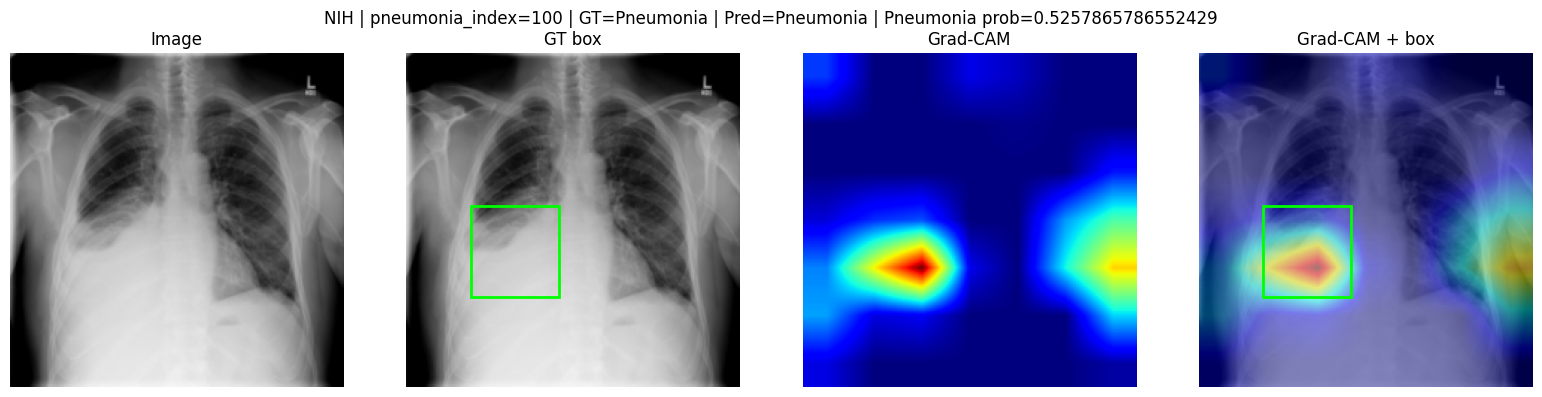

,100
patient_id,00012576_004
image_id,00012576_004.png
image_path,/content/datasets/NIH_Extracted/images/0001257...
cam_path,results/nih/gradcam/cams/00012576_004.npy
gt_label,1
gt_class,Pneumonia
has_bbox,True
pred_label,1
pred_class,Pneumonia
correct,1


In [9]:
show_xai("nih", "gradcam", 100)

In [13]:
RESULTS_ROOT = Path("/content/Computer_vision_final/results")


def box_to_mask(box, shape=(224, 224)):
    mask = np.zeros(shape, dtype=bool)

    x1 = int(round(box["x"]))
    y1 = int(round(box["y"]))
    x2 = int(round(box["x"] + box["width"]))
    y2 = int(round(box["y"] + box["height"]))

    x1 = max(0, min(shape[1], x1))
    x2 = max(0, min(shape[1], x2))
    y1 = max(0, min(shape[0], y1))
    y2 = max(0, min(shape[0], y2))

    mask[y1:y2, x1:x2] = True
    return mask


def evaluate_xai_bbox_coverage(dataset="nih", method="gradcam", top_percent=15, bbox_threshold=0.5):
    root = RESULTS_ROOT / dataset / method
    meta = pd.read_csv(root / "metadata.csv")
    meta = meta[meta["gt_label"] == 1].reset_index(drop=True)

    rows = []

    for i, row in meta.iterrows():
        heat_path = row["cam_path"] if method == "gradcam" else row["ig_path"]
        heat = np.load(heat_path).astype(np.float32)

        boxes = json.loads(row["display_boxes_json"])
        if len(boxes) == 0:
            continue

        heat = heat - heat.min()
        heat = heat / (heat.max() + 1e-8)

        thresh = np.percentile(heat, 100 - top_percent)
        xai_mask = heat >= thresh

        best = {
            "bbox_covered_by_xai": -1,
            "energy_in_bbox": -1,
            "iou_top": -1,
            "best_box_idx": None,
        }

        for box_idx, box in enumerate(boxes):
            box_mask = box_to_mask(box, heat.shape)

            inter = np.logical_and(xai_mask, box_mask).sum()
            union = np.logical_or(xai_mask, box_mask).sum()

            bbox_covered_by_xai = inter / (box_mask.sum() + 1e-8)
            energy_in_bbox = heat[box_mask].sum() / (heat.sum() + 1e-8)
            iou = inter / (union + 1e-8)

            if bbox_covered_by_xai > best["bbox_covered_by_xai"]:
                best = {
                    "bbox_covered_by_xai": float(bbox_covered_by_xai),
                    "energy_in_bbox": float(energy_in_bbox),
                    "iou_top": float(iou),
                    "best_box_idx": int(box_idx),
                }

        rows.append({
            "dataset": dataset,
            "method": method,
            "idx_in_pneumonia": i,
            "patient_id": row["patient_id"],
            "gt_class": row["gt_class"],
            "pred_class": row["pred_class"],
            "pneumonia_probability": row.get("pneumonia_probability", np.nan),
            "correct": row.get("correct", np.nan),
            "num_boxes": len(boxes),
            "good_bbox_localization": int(best["bbox_covered_by_xai"] >= bbox_threshold),
            **best,
        })

    out = pd.DataFrame(rows)

    summary = {
        "dataset": dataset,
        "method": method,
        "n_images": len(out),
        "top_percent": top_percent,
        "bbox_threshold": bbox_threshold,
        "good_bbox_localization_rate": out["good_bbox_localization"].mean(),
        "mean_bbox_covered_by_xai": out["bbox_covered_by_xai"].mean(),
        "median_bbox_covered_by_xai": out["bbox_covered_by_xai"].median(),
        "mean_energy_in_bbox": out["energy_in_bbox"].mean(),
        "median_energy_in_bbox": out["energy_in_bbox"].median(),
        "mean_iou_top": out["iou_top"].mean(),
        "median_iou_top": out["iou_top"].median(),
    }

    return out, summary


all_summaries = []
all_bbox_details = {}

for dataset in ["nih", "rsna"]:
    for method in ["gradcam", "integrated_gradients"]:
        details, summary = evaluate_xai_bbox_coverage(
            dataset=dataset,
            method=method,
            top_percent=15,
            bbox_threshold=0.5,
        )
        all_bbox_details[(dataset, method)] = details
        all_summaries.append(summary)

bbox_summary_df = pd.DataFrame(all_summaries)
bbox_summary_df

,dataset,method,n_images,top_percent,bbox_threshold,good_bbox_localization_rate,mean_bbox_covered_by_xai,median_bbox_covered_by_xai,mean_energy_in_bbox,median_energy_in_bbox,mean_iou_top,median_iou_top
0,nih,gradcam,120,15,0.5,0.516667,0.533739,0.618011,0.222342,0.178572,0.211023,0.193621
1,nih,integrated_gradients,120,15,0.5,0.050000,0.282997,0.269237,0.137483,0.091046,0.096509,0.086269
2,rsna,gradcam,902,15,0.5,0.834812,0.727184,0.741593,0.215001,0.208935,0.247409,0.247154
3,rsna,integrated_gradients,902,15,0.5,0.297118,0.416564,0.395551,0.148067,0.135865,0.131921,0.128011


In [21]:
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from tqdm import tqdm
from torchvision import transforms


ROOT = Path("/content/Computer_vision_final")
RESULTS = ROOT / "results"
OUT = ROOT / "xai_visuals_compressed"

display_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
])


def draw_one(row, method, out_path):
    img = Image.open(row["image_path"]).convert("RGB")
    img = display_tf(img)
    img = np.array(img).astype(np.float32) / 255.0

    heat_path = row["cam_path"] if method == "gradcam" else row["ig_path"]
    heat = np.load(heat_path)

    boxes = json.loads(row["display_boxes_json"])

    heat_rgb = cv2.applyColorMap(np.uint8(255 * heat), cv2.COLORMAP_JET)
    heat_rgb = cv2.cvtColor(heat_rgb, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    overlay = np.clip(0.55 * img + 0.45 * heat_rgb, 0, 1)

    fig, axs = plt.subplots(1, 4, figsize=(10, 2.8))

    axs[0].imshow(img, cmap="gray")
    axs[0].set_title("Image", fontsize=8)

    axs[1].imshow(img, cmap="gray")
    axs[1].set_title("GT bbox", fontsize=8)

    axs[2].imshow(heat, cmap="jet")
    axs[2].set_title("Grad-CAM" if method == "gradcam" else "IG", fontsize=8)

    axs[3].imshow(overlay)
    axs[3].set_title("Overlay", fontsize=8)

    for ax in [axs[1], axs[3]]:
        for b in boxes:
            ax.add_patch(
                patches.Rectangle(
                    (b["x"], b["y"]),
                    b["width"],
                    b["height"],
                    linewidth=1.5,
                    edgecolor="lime",
                    facecolor="none",
                )
            )

    for ax in axs:
        ax.axis("off")

    prob = row.get("pneumonia_probability", "NA")
    if prob != "NA":
        prob = round(float(prob), 3)

    status = "Correct" if int(row["correct"]) == 1 else "Incorrect"

    plt.suptitle(
        f"{status} | GT: {row.get('gt_class')} | Pred: {row.get('pred_class')} | P: {prob}",
        fontsize=9,
    )
    plt.tight_layout()

    tmp_path = str(out_path).replace(".jpg", "_tmp.png")

    fig.savefig(tmp_path, dpi=100, bbox_inches="tight")
    plt.close(fig)

    Image.open(tmp_path).convert("RGB").save(
        out_path,
        "JPEG",
        quality=75,
        optimize=True,
    )

    Path(tmp_path).unlink()


def save_visuals(dataset, method, only_pneumonia=True):
    src = RESULTS / dataset / method / "metadata.csv"
    meta = pd.read_csv(src)

    if only_pneumonia:
        meta = meta[meta["gt_label"] == 1].reset_index(drop=True)

    for i, row in tqdm(meta.iterrows(), total=len(meta), desc=f"{dataset}-{method}"):
        status_dir = "correct" if int(row["correct"]) == 1 else "incorrect"
        dst = OUT / dataset / method / status_dir
        dst.mkdir(parents=True, exist_ok=True)

        patient_id = row["patient_id"]
        out_path = dst / f"{i:04d}_{patient_id}.jpg"

        draw_one(row, method, out_path)

    correct_count = len(list((OUT / dataset / method / "correct").glob("*.jpg")))
    incorrect_count = len(list((OUT / dataset / method / "incorrect").glob("*.jpg")))

    print(dataset, method)
    print("correct:", correct_count)
    print("incorrect:", incorrect_count)


for dataset in ["nih", "rsna"]:
    for method in ["gradcam", "integrated_gradients"]:
        save_visuals(dataset, method, only_pneumonia=True)

nih-gradcam: 100%|██████████| 120/120 [00:33<00:00,  3.62it/s]


nih gradcam
correct: 97
incorrect: 23


nih-integrated_gradients: 100%|██████████| 120/120 [00:36<00:00,  3.31it/s]


nih integrated_gradients
correct: 97
incorrect: 23


rsna-gradcam: 100%|██████████| 902/902 [04:18<00:00,  3.49it/s]


rsna gradcam
correct: 735
incorrect: 167


rsna-integrated_gradients: 100%|██████████| 902/902 [04:30<00:00,  3.33it/s]

rsna integrated_gradients
correct: 735
incorrect: 167


In [24]:
!zip -r /content/drive/MyDrive/CVP/xai_visuals_compressed.zip xai_visuals_compressed

  adding: xai_visuals_compressed/ (stored 0%)
  adding: xai_visuals_compressed/rsna/ (stored 0%)
  adding: xai_visuals_compressed/rsna/integrated_gradients/ (stored 0%)
  adding: xai_visuals_compressed/rsna/integrated_gradients/correct/ (stored 0%)
  adding: xai_visuals_compressed/rsna/integrated_gradients/correct/0688_50cbc243-6654-4b10-b063-95b939f9eeca.jpg (deflated 4%)
  adding: xai_visuals_compressed/rsna/integrated_gradients/correct/0651_0a9c4c04-5918-48da-9ba1-b2a3add66ae9.jpg (deflated 6%)
  adding: xai_visuals_compressed/rsna/integrated_gradients/correct/0513_3e8eea71-b36a-49a9-8fbc-47749ee2c641.jpg (deflated 4%)
  adding: xai_visuals_compressed/rsna/integrated_gradients/correct/0388_7eb0abcb-860e-4745-b311-28657770c038.jpg (deflated 5%)
  adding: xai_visuals_compressed/rsna/integrated_gradients/correct/0392_c98faad9-6dd2-45fe-87af-63bbb94eeb77.jpg (deflated 4%)
  adding: xai_visuals_compressed/rsna/integrated_gradients/correct/0163_a66d881d-c072-4ea0-a00c-74a62981a3e8.jpg (de